# BAB IV — Klasifikasi Software Inventory GLPI

**Metodologi:** CRISP-DM | **Model:** TF-IDF + Logistic Regression / Linear SVM | **Pendekatan:** Semi-Supervised Self-Training

**Data penelitian:** 12.318 baris GLPI → 9.256 software unik (seluruhnya tetap digunakan). Seluruh 9.256 software dibagi langsung menggunakan `train_test_split(katalog, test_size=0.20)` menjadi **training pool 80%** dan **testing pool 20%**; bukan melakukan split hanya pada 200 label. Label awal dari IT tidak harus mencakup semua software. **Akurasi hanya dihitung dari baris testing yang memiliki label referensi**.

**Cara menjalankan di VS Code:** buka folder project → buka notebook ini → **Select Kernel** (Python) → jalankan cell dari atas ke bawah. Letakkan `SoftwareDataset.csv`, `Audit_67_Rule_Software_Dictionary.csv`, dan `IT_Validation_200.xlsx` di folder yang sama. File label 200 **tidak disertakan** karena tidak tersedia di lampiran yang kami pegang.

**Instalasi melalui Terminal VS Code (sekali saja):**

```powershell
python -m pip install numpy pandas matplotlib scikit-learn openpyxl joblib ipython ipykernel
```

**Penting:** Contoh/prediksi otomatis bukan kebenaran IT. Aturan GLPI `Ignore import` hanya dianalisis, **tidak dieksekusi** pada GLPI produksi. Hasil evaluasi dari label awal yang pernah diperiksa saat pengembangan bersifat **evaluasi awal**, bukan estimasi final independen.

## 4.1 Business Understanding

Penelitian bertujuan membantu IT memilah aplikasi utama yang perlu ditampilkan dalam laporan inventory (**INCLUDE**) dan entri pendukung yang **perlu ditinjau** untuk pengecualian (**EXCLUDE_CANDIDATE**). Model tidak menghapus software dan tidak mengubah GLPI.

## 4.2 Data Understanding dan Exploratory Data Analysis (EDA)

### KODE 01 — Import Library dan Folder

**Tujuan:** Menyiapkan library serta folder hasil.  
**Output:** Folder `hasil_bab4`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
BASE = Path.cwd()
HASIL = BASE / 'hasil_bab4'
HASIL.mkdir(exist_ok=True)
print('Folder kerja:', BASE)

Folder kerja: c:\Users\magang.tiga\Documents\CODE_GLPI


### KODE 02 — Memuat Dataset GLPI

**Tujuan:** Membaca data software yang akan diteliti.  
**Output:** Jumlah dan lima data pertama.

In [2]:
file_data = BASE / 'SoftwareDataset.csv'
if not file_data.exists():
    raise FileNotFoundError('SoftwareDataset.csv belum ada di folder project VS Code.')

data = pd.read_csv(file_data, dtype=str).fillna('')
print('Jumlah baris awal:', len(data))
display(data.head())

Jumlah baris awal: 12318


,software_id,software_name,manufacturer,software_category,entity_id
0,72,,Microsoft,License,0
1,"36,057",,,,0
2,"36,006",(244) hafid.algofiri@cemindo.com,mail.cemindo.com,none,0
3,"35,990",{01ef7197-4deb-4997-a10c-3627ffe1b4c8},,application,0
4,"36,039",{05F81C27-62A5-4A0C-8519-60CB66CF87C6},,application,0


### KODE 03 — Memeriksa Struktur Dataset

**Tujuan:** Mengecek kolom, tipe data dan isi kosong.  
**Output:** Tabel kondisi data awal.

In [3]:
print('Ukuran dataset:', data.shape)
print('Kolom:', list(data.columns))
kosong = data.eq('').sum().rename('jumlah_kosong')
display(kosong.to_frame())

Ukuran dataset: (12318, 5)
Kolom: ['software_id', 'software_name', 'manufacturer', 'software_category', 'entity_id']


,jumlah_kosong
software_id,0
software_name,2
manufacturer,681
software_category,3465
entity_id,0


### KODE 04 — Memeriksa Duplikasi Software

**Tujuan:** Menghitung nama software berulang dan nama kosong.  
**Output:** Ringkasan duplikasi.

In [4]:
nama_awal = data['software_name'].str.strip().str.lower()
print('Nama software kosong:', (nama_awal == '').sum())
print('Nama software unik (awal):', nama_awal[nama_awal != ''].nunique())
print('Baris nama berulang:', nama_awal[nama_awal != ''].duplicated().sum())

Nama software kosong: 2
Nama software unik (awal): 9322
Baris nama berulang: 2994


### KODE 05 — EDA Kategori dan Manufacturer

**Tujuan:** Melihat kategori dan vendor software terbanyak.  
**Output:** Dua tabel dan dua grafik.

,jumlah
software_category,
application,4108
Tidak diketahui,3465
system_component,2234
store,1299
system,590
License,258
developer,240
none,58
libraries,38


,jumlah
manufacturer,
Microsoft Corporation,2079
Tidak diketahui,681
Siemens AG,503
AUTODESK,497
Python Software Foundation,458
Microsoft,422
Corel Corporation,402
Microsoft Platform Extensions,329
Adobe Systems Incorporated,245


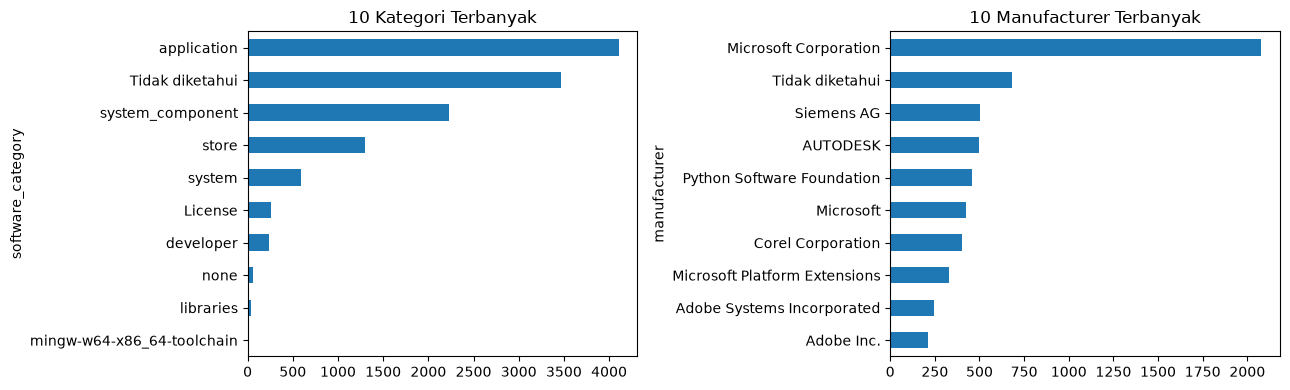

In [5]:
kategori = data['software_category'].replace('', 'Tidak diketahui').value_counts().head(10)
vendor = data['manufacturer'].replace('', 'Tidak diketahui').value_counts().head(10)
display(kategori.to_frame('jumlah'))
display(vendor.to_frame('jumlah'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
kategori.sort_values().plot.barh(ax=ax[0], title='10 Kategori Terbanyak')
vendor.sort_values().plot.barh(ax=ax[1], title='10 Manufacturer Terbanyak')
plt.tight_layout()
plt.savefig(HASIL / 'EDA_Kategori_Vendor.png', dpi=150)
plt.show()

### KODE 06 — EDA Panjang Nama Software

**Tujuan:** Mengetahui variasi panjang nama software.  
**Output:** Statistik dan histogram.

count    12316.0
mean        28.5
std         16.7
min          2.0
25%         16.0
50%         26.0
75%         37.0
max        125.0
Name: software_name, dtype: float64


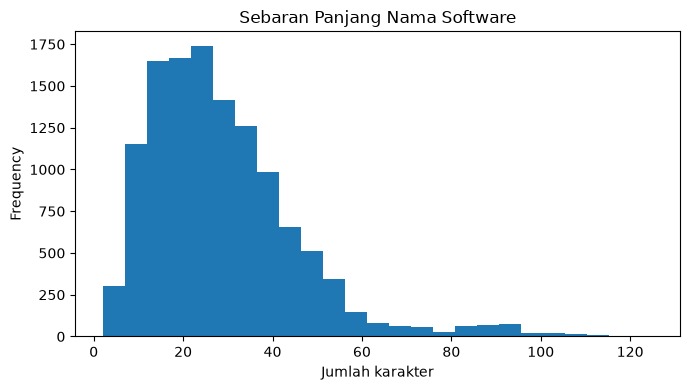

In [7]:
panjang = data.loc[data['software_name'].str.strip() != '', 'software_name'].str.len()
print(panjang.describe().round(1))
panjang.plot.hist(bins=25, figsize=(7, 4), title='Sebaran Panjang Nama Software')
plt.xlabel('Jumlah karakter')
plt.tight_layout()
plt.savefig(HASIL / 'EDA_Panjang_Nama.png', dpi=150)
plt.show()

## 4.3 Data Preparation

### KODE 07 — Pembersihan dan Normalisasi

**Tujuan:** Membersihkan teks dan menyatukan nama software yang sama.  
**Output:** Katalog nama software unik.

In [8]:
def normalisasi(teks):
    return re.sub(r'\s+', ' ', str(teks).strip().lower())

data['name_key'] = data['software_name'].map(normalisasi)
bersih = data[data['name_key'] != ''].copy()

# Satu baris per nama software; metadata diambil dari baris yang tidak kosong.
def pilih_isi(kolom):
    isi = kolom[kolom.str.strip() != '']
    return isi.iloc[0] if len(isi) else ''

katalog = bersih.groupby('name_key', as_index=False).agg({
    'software_name': pilih_isi,
    'manufacturer': pilih_isi,
    'software_category': pilih_isi,
    'software_id': 'first',
    'entity_id': 'first'
})
katalog['teks'] = (katalog['software_name'] + ' ' + katalog['manufacturer']).str.strip()
print('Jumlah software unik:', len(katalog))
display(katalog.head())

Jumlah software unik: 9256


,name_key,software_name,manufacturer,software_category,software_id,entity_id,teks
0,(244) hafid.algofiri@cemindo.com,(244) hafid.algofiri@cemindo.com,mail.cemindo.com,none,"36,006",0,(244) hafid.algofiri@cemindo.com mail.cemindo.com
1,010 editor 6.0.3 (64-bit),010 Editor 6.0.3 (64-bit),SweetScape Software,application,"36,241",0,010 Editor 6.0.3 (64-bit) SweetScape Software
2,0d9a1b2d.pdfreaderuwp,0D9A1B2D.PDFReaderUWP,Kdan Mobile Software Ltd.,store,"33,429",0,0D9A1B2D.PDFReaderUWP Kdan Mobile Software Ltd.
3,1 file viewer,1 File Viewer,regulars,store,"25,336",0,1 File Viewer regulars
4,10.10.10.5/gas/wa/r/gdc-tiptop-udm-intranet,10.10.10.5/gas/wa/r/gdc-tiptop-udm-intranet,10.10.10.5,none,"20,117",0,10.10.10.5/gas/wa/r/gdc-tiptop-udm-intranet 10...


### KODE 08 — Menyimpan Data Bersih

**Tujuan:** Menyimpan katalog untuk dokumentasi penelitian.  
**Output:** CSV hasil preprocessing.

In [9]:
katalog.to_csv(HASIL / '01_Katalog_Software_Unik.csv', index=False)
print('Tersimpan:', HASIL / '01_Katalog_Software_Unik.csv')

Tersimpan: c:\Users\magang.tiga\Documents\CODE_GLPI\hasil_bab4\01_Katalog_Software_Unik.csv


### KODE 09 — Membaca Software Dictionary

**Tujuan:** Mengambil aturan GLPI sebagai pembanding, bukan ground truth.  
**Output:** Jumlah aturan Ignore import.

In [11]:
file_dict = BASE / 'Rule_Software_Dictionary.csv'
aturan = pd.read_csv(file_dict, dtype=str).fillna('')
print('Jumlah aturan tercatat:', len(aturan))

aturan_ignore = aturan[
    aturan['action'].str.lower().eq('ignore import') &
    aturan['active_in_user_paste'].str.lower().eq('yes')
].copy()
print('Aturan Ignore import aktif dalam data:', len(aturan_ignore))
display(aturan_ignore[['rule_id','criteria_field','operator','pattern']].head())

Jumlah aturan tercatat: 67
Aturan Ignore import aktif dalam data: 65


,rule_id,criteria_field,operator,pattern
0,210,Software,is,PrimoPDF
1,211,Software,starting with,KB
2,231,Software,starting with,Microsoft Family
3,232,Software,contains,Update for Microsoft
4,233,Software,contains,Visual C


### KODE 10 — Pencocokan Aturan Dictionary

**Tujuan:** Mengetahui software yang cocok dengan pola ignore import.  
**Output:** Jumlah cocok dan tidak cocok.

In [12]:
katalog['dictionary_rule_id'] = ''
for _, a in aturan_ignore.iterrows():
    kolom = {'software': 'software_name',
             'publisher': 'manufacturer',
             'category from inventory tool': 'software_category'}.get(a['criteria_field'].lower())
    if kolom is None or not a['pattern'].strip():
        continue

    teks = katalog[kolom].str.lower()
    pola = a['pattern'].lower()
    if a['operator'].lower() == 'contains':
        cocok = teks.str.contains(pola, regex=False, na=False)
    elif a['operator'].lower() == 'starting with':
        cocok = teks.str.startswith(pola, na=False)
    elif a['operator'].lower() == 'is':
        cocok = teks.eq(pola)
    else:
        continue

    baru = cocok & katalog['dictionary_rule_id'].eq('')
    katalog.loc[baru, 'dictionary_rule_id'] = str(a['rule_id'])

katalog['dictionary_hit'] = katalog['dictionary_rule_id'].ne('')
print(katalog['dictionary_hit'].value_counts().rename({True:'Cocok',False:'Tidak cocok'}))
katalog.to_csv(HASIL / '02_Audit_Dictionary.csv', index=False)

dictionary_hit
Tidak cocok    6886
Cocok          2370
Name: count, dtype: int64


### KODE 11 — Memuat Label Awal IT

**Tujuan:** Memasukkan contoh keputusan INCLUDE/EXCLUDE dari file IT.  
**Output:** Jumlah label dan status kesiapan model.

In [13]:
file_label = next((BASE / x for x in [
    'IT_Validation_200.xlsx', 'IT_Validation_200.csv',
    'Label_IT_200.xlsx', 'Label_IT_200.csv'
] if (BASE / x).exists()), None)

print('File label ditemukan:', file_label)
label_it = pd.DataFrame(columns=['name_key', 'label_id'])
if file_label is None:
    template = katalog.sample(n=min(200, len(katalog)), random_state=RANDOM_STATE)[
        ['software_name','manufacturer','software_category']
    ].copy()
    template['label_final_it'] = ''
    template.to_excel(HASIL / 'Template_Label_IT_200.xlsx', index=False)
    print('File label IT belum ditemukan.')
    print('Contoh format dibuat di:', HASIL / 'Template_Label_IT_200.xlsx')
else:
    mentah = pd.read_excel(file_label, dtype=str).fillna('') if file_label.suffix == '.xlsx'         else pd.read_csv(file_label, dtype=str).fillna('')
    nama_col = 'software_name' if 'software_name' in mentah.columns else 'name_key'
    label_col = next((x for x in ['label_final_it','label_it','label','label_final']
                      if x in mentah.columns), None)
    if nama_col not in mentah.columns or label_col is None:
        raise ValueError('Label IT perlu kolom software_name dan label_final_it.')

    mentah['name_key'] = mentah[nama_col].map(normalisasi)
    nilai = mentah[label_col].str.upper().str.strip()
    mapping = {'INCLUDE':0,'KEEP':0,'0':0,
               'EXCLUDE':1,'EXCLUDE_CANDIDATE':1,'IGNORE':1,'1':1}
    mentah['label_id'] = nilai.map(mapping)
    terisi = mentah.dropna(subset=['label_id']).copy()
    konflik = terisi.groupby('name_key')['label_id'].nunique()
    if (konflik > 1).any():
        raise ValueError('Ada nama software dengan dua label IT berbeda. Periksa file label.')
    terisi = terisi.drop_duplicates('name_key')
    label_it = terisi[['name_key','label_id']].merge(
        katalog[['name_key']], on='name_key', how='inner')
    label_it['label_id'] = label_it['label_id'].astype(int)
    print('Label terisi:', len(terisi), '| Cocok dengan katalog:', len(label_it))
    print('Tidak cocok:', len(terisi) - len(label_it))
    print(label_it['label_id'].map({0:'INCLUDE',1:'EXCLUDE'}).value_counts())

siap = (len(label_it) >= 30 and label_it['label_id'].value_counts().min() >= 5
        and label_it['label_id'].nunique() == 2)
print('Siap untuk modeling:', siap)

File label ditemukan: c:\Users\magang.tiga\Documents\CODE_GLPI\IT_Validation_200.xlsx
Label terisi: 200 | Cocok dengan katalog: 200
Tidak cocok: 0
label_id
INCLUDE    114
EXCLUDE     86
Name: count, dtype: int64
Siap untuk modeling: True


### KODE 12 — Train-Test Split dari 9.256 Software Bersih
**Tujuan:** Membagi **seluruh katalog software unik**, bukan hanya 200 data berlabel, menjadi 80% training dan 20% testing.

**Output:** Jumlah software dan label IT pada masing-masing kelompok.

In [14]:
# Seluruh 9.256 software tetap dibagi, termasuk yang belum berlabel.
# Stratify menjaga proporsi label 0, 1, dan data tanpa label.
katalog = katalog.drop(columns=['label_id'], errors='ignore').merge(
    label_it, on='name_key', how='left'
)
kelompok = katalog['label_id'].fillna(-1).astype(int)
strata = kelompok if kelompok.value_counts().min() >= 2 else None

train_pool, test_pool = train_test_split(
    katalog, test_size=0.20, random_state=RANDOM_STATE,
    shuffle=True, stratify=strata
)
train_pool = train_pool.reset_index(drop=True)
test_pool = test_pool.reset_index(drop=True)

print('Total software bersih:', len(katalog))
print('Training pool:', len(train_pool))
print('Testing pool:', len(test_pool))
print('Label di training:\n', train_pool['label_id'].value_counts(dropna=False))
print('Label di testing:\n', test_pool['label_id'].value_counts(dropna=False))

# Model harus punya contoh label 0 dan 1 di bagian training.
hitung = train_pool['label_id'].value_counts().reindex([0, 1], fill_value=0)
siap = (hitung >= 3).all()
print('Siap untuk modeling:', siap)
if not siap:
    print('Periksa file label IT dan kecocokan nama software pada KODE 11.')

assert len(train_pool) + len(test_pool) == len(katalog)
assert set(train_pool['name_key']).isdisjoint(set(test_pool['name_key']))

Total software bersih: 9256
Training pool: 7404
Testing pool: 1852
Label di training:
 label_id
NaN    7244
0.0      91
1.0      69
Name: count, dtype: int64
Label di testing:
 label_id
NaN    1812
0.0      23
1.0      17
Name: count, dtype: int64
Siap untuk modeling: True


### KODE 13 — Menyimpan Hasil Pembagian Data

**Tujuan:** Mendokumentasikan pembagian dataset.  
**Output:** Dua CSV train-test.

In [15]:
train_pool.to_csv(HASIL / '03_Training_Pool.csv', index=False)
test_pool.to_csv(HASIL / '04_Testing_Pool.csv', index=False)
print('Pembagian disimpan. Testing tidak digunakan untuk training.')

Pembagian disimpan. Testing tidak digunakan untuk training.


## 4.4 Modeling

**Catatan:** Model memakai label IT di training pool, kemudian mencoba memilih *pseudo-label* dari software tanpa label **di training pool saja**. Model tidak dipaksa menambahkan label jika keyakinannya rendah. `LinearSVC` dikalibrasi agar dapat digunakan untuk self-training berbasis probabilitas.

### KODE 14 — Ekstraksi Fitur TF-IDF

**Tujuan:** Mengubah nama dan manufacturer menjadi fitur numerik.  
**Output:** Matriks TF-IDF dari training pool.

In [16]:
if siap:
    tfidf = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5),
                            min_df=2, max_features=15000)
    X_train = tfidf.fit_transform(train_pool['teks'])
    X_test = tfidf.transform(test_pool['teks'])
    y_train = train_pool['label_id'].fillna(-1).astype(int).to_numpy()
    print('Ukuran TF-IDF training:', X_train.shape)
    print('Label training (0=INCLUDE, 1=EXCLUDE, -1=belum berlabel):')
    print(pd.Series(y_train).value_counts().sort_index())
else:
    print('Belum bisa modeling: pastikan file label IT ada dan kedua kelas cocok.')

Ukuran TF-IDF training: (7404, 15000)
Label training (0=INCLUDE, 1=EXCLUDE, -1=belum berlabel):
-1    7244
 0      91
 1      69
Name: count, dtype: int64


### KODE 15 — Menyiapkan Dua Algoritma

**Tujuan:** Mendefinisikan Logistic Regression dan Linear SVM.  
**Output:** Dua algoritma siap dilatih.

In [17]:
if siap:
    algoritma = {
        'Logistic Regression': LogisticRegression(
            max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
        'Linear SVM': CalibratedClassifierCV(
            LinearSVC(class_weight='balanced', random_state=RANDOM_STATE), cv=3)
    }
    print('Algoritma:', ', '.join(algoritma))

Algoritma: Logistic Regression, Linear SVM


### KODE 16 — Semi-Supervised Self-Training

**Tujuan:** Memanfaatkan data training yang belum berlabel secara hati-hati.  
**Output:** Model terlatih dan jumlah pseudo-label.

In [18]:
model = {}
jumlah_pseudo = {}
if siap:
    contoh_berlabel = pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0)
    print('Contoh berlabel di training:', contoh_berlabel.to_dict())
    if (contoh_berlabel < 3).any():
        raise ValueError('Training belum punya cukup label 0 dan 1. Jalankan ulang KODE 11, 12, 14.')

    for nama, algoritma_awal in algoritma.items():
        m = SelfTrainingClassifier(algoritma_awal, threshold=0.90, max_iter=5)
        m.fit(X_train, y_train)
        model[nama] = m
        jumlah_pseudo[nama] = int(((y_train == -1) & (m.transduction_ != -1)).sum())
        print(nama, '| pseudo-label:', jumlah_pseudo[nama], '| iterasi:', m.n_iter_)
else:
    print('Model tidak dijalankan: label training belum mencukupi.')

Contoh berlabel di training: {0: 91, 1: 69}
Logistic Regression | pseudo-label: 0 | iterasi: 1
Linear SVM | pseudo-label: 0 | iterasi: 1


### KODE 17 — Melihat Hasil Pseudo-Label

**Tujuan:** Memisahkan label asli dari label prediksi model.  
**Output:** Ringkasan sumber label training.

In [19]:
if siap:
    tabel_pseudo = train_pool[['software_name','manufacturer','label_id']].copy()
    tabel_pseudo['label_model_lr'] = model['Logistic Regression'].transduction_
    tabel_pseudo['sumber'] = np.where(
        tabel_pseudo['label_id'].notna(), 'LABEL_AWAL_IT',
        np.where(tabel_pseudo['label_model_lr'] != -1, 'PSEUDO_LABEL', 'UNLABELED'))
    display(tabel_pseudo['sumber'].value_counts().to_frame('jumlah'))
    tabel_pseudo.to_csv(HASIL / '05_Status_Label_Training.csv', index=False)

,jumlah
sumber,
UNLABELED,7244
LABEL_AWAL_IT,160


## 4.5 Evaluation

**Penting:** Jumlah testing pool adalah 20% dari 9.256 software. Namun, metrik evaluasi hanya dihitung dari bagian testing yang memiliki label IT. Hasil dari 40 label (bila terdapat 200 label awal) adalah **evaluasi awal**, bukan validasi final independen.

### KODE 18 — Prediksi Data Testing

**Tujuan:** Membuat prediksi untuk seluruh testing pool tanpa melatih pada data tersebut.  
**Output:** CSV hasil prediksi testing.

In [20]:
if siap:
    prediksi_test = test_pool[['name_key','software_name','label_id','dictionary_hit']].copy()
    for nama, m in model.items():
        prediksi_test[nama] = m.predict(X_test)
    prediksi_test.to_csv(HASIL / '06_Prediksi_Testing.csv', index=False)
    display(prediksi_test.head())

,name_key,software_name,label_id,dictionary_hit,Logistic Regression,Linear SVM
0,smartconnectextinstaller,SmartConnectExtInstaller,NaN,False,1,1
1,microsoft windows desktop targeting pack - 7.0...,Microsoft Windows Desktop Targeting Pack - 7.0...,NaN,True,1,1
2,alienware digital delivery,Alienware Digital Delivery,NaN,False,1,0
3,sticky password 8.7.2.1536,Sticky Password 8.7.2.1536,NaN,False,1,0
4,python 3.11.2 executables (64-bit),Python 3.11.2 Executables (64-bit),NaN,True,0,0


### KODE 19 — Evaluasi Logistic Regression dan SVM

**Tujuan:** Mengukur accuracy, precision, recall, dan F1 pada referensi IT.  
**Output:** Tabel perbandingan kedua model.

In [21]:
hasil_evaluasi = pd.DataFrame()
if siap:
    posisi = test_pool['label_id'].notna().to_numpy()
    y_true = test_pool.loc[posisi, 'label_id'].astype(int)
    ringkasan = []
    for nama, m in model.items():
        y_pred = m.predict(X_test[posisi])
        ringkasan.append({
            'Model': nama,
            'Accuracy': round(accuracy_score(y_true, y_pred), 3),
            'Macro F1': round(f1_score(y_true, y_pred, average='macro', zero_division=0), 3),
            'Recall EXCLUDE': round(
                classification_report(y_true, y_pred, labels=[0,1],
                                      output_dict=True, zero_division=0)['1']['recall'], 3),
            'Data Uji Berlabel': len(y_true)
        })
    hasil_evaluasi = pd.DataFrame(ringkasan)
    display(hasil_evaluasi)
    hasil_evaluasi.to_csv(HASIL / '07_Evaluasi_Model.csv', index=False)

,Model,Accuracy,Macro F1,Recall EXCLUDE,Data Uji Berlabel
0,Logistic Regression,0.70,0.697,0.706,40
1,Linear SVM,0.55,0.436,0.118,40


### KODE 20 — Confusion Matrix dan Classification Report

**Tujuan:** Menganalisis kesalahan INCLUDE dan EXCLUDE.  
**Output:** Grafik serta classification report.


 Logistic Regression
                   precision    recall  f1-score   support

          INCLUDE       0.76      0.70      0.73        23
EXCLUDE_CANDIDATE       0.63      0.71      0.67        17

         accuracy                           0.70        40
        macro avg       0.70      0.70      0.70        40
     weighted avg       0.71      0.70      0.70        40


 Linear SVM
                   precision    recall  f1-score   support

          INCLUDE       0.57      0.87      0.69        23
EXCLUDE_CANDIDATE       0.40      0.12      0.18        17

         accuracy                           0.55        40
        macro avg       0.49      0.49      0.44        40
     weighted avg       0.50      0.55      0.47        40



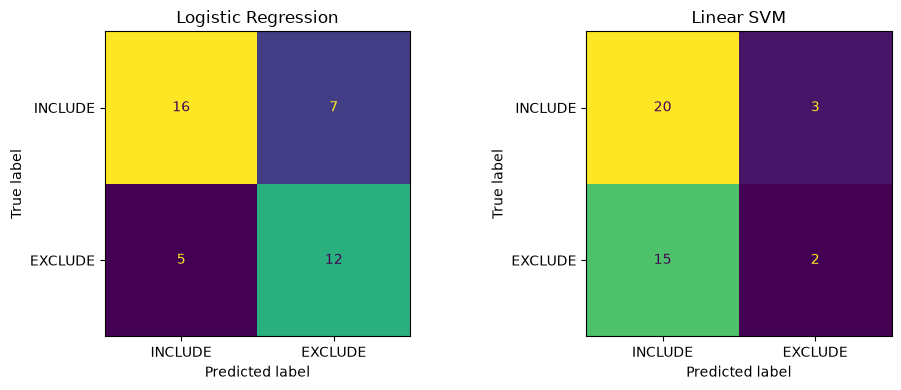

In [22]:
if siap:
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for indeks, (nama, m) in enumerate(model.items()):
        y_pred = m.predict(X_test[posisi])
        print('\n', nama)
        print(classification_report(y_true, y_pred,
              labels=[0,1], target_names=['INCLUDE','EXCLUDE_CANDIDATE'],
              zero_division=0))
        ConfusionMatrixDisplay.from_predictions(
            y_true, y_pred, labels=[0,1],
            display_labels=['INCLUDE','EXCLUDE'], ax=ax[indeks], colorbar=False)
        ax[indeks].set_title(nama)
    plt.tight_layout()
    plt.savefig(HASIL / 'Evaluasi_Confusion_Matrix.png', dpi=150)
    plt.show()

### KODE 21 — Menganalisis Salah Prediksi

**Tujuan:** Melihat contoh software yang salah diprediksi.  
**Output:** Tabel kesalahan untuk pembahasan.

In [23]:
if siap:
    nama_model = hasil_evaluasi.sort_values('Macro F1', ascending=False).iloc[0]['Model']
    y_pred = model[nama_model].predict(X_test[posisi])
    salah = test_pool.loc[posisi, ['software_name','manufacturer','label_id']].copy()
    salah['prediksi'] = y_pred
    salah = salah[salah['label_id'] != salah['prediksi']]
    print('Jumlah kesalahan:', len(salah))
    display(salah.head(15))
    salah.to_csv(HASIL / '08_Salah_Prediksi.csv', index=False)

Jumlah kesalahan: 12


,software_name,manufacturer,label_id,prediksi
109,Fish and Corals,Microsoft Corporation,1.0,0
162,AmiBroker 5.60.3,AmiBroker.com,0.0,1
385,Siemens Totally Integrated Automation Portal V...,Siemens AG,0.0,1
412,Primerose Lake,WildTangent,0.0,1
1037,Fixed Asset Management System ver 2.1,Excelsoft Technology,0.0,1
1120,OMNITREND Center Server,PRUFTECHNIK,1.0,0
1128,PuTTY release 0.70 (64-bit),Simon Tatham,1.0,0
1329,Fantastical Fantasy,Microsoft Corporation,1.0,0
1554,ExifPro 2.1 Photo Viewer,,0.0,1
1556,AMD WVR64,"Advanced Micro Devices, Inc.",0.0,1


## 4.6 Deployment — Prototipe Rekomendasi Software

Penerapan dilakukan **secara batch pada file CSV/Excel**, bukan mengubah database atau Dictionary GLPI secara otomatis. Status `REVIEW` digunakan untuk prediksi yang belum meyakinkan atau tidak sejalan dengan pola Dictionary.

### KODE 22 — Memilih Model dan Memprediksi Katalog

**Tujuan:** Membuat rekomendasi untuk seluruh 9.256 software.  
**Output:** Prediksi dan keyakinan model.

In [24]:
if siap:
    model_terbaik = hasil_evaluasi.sort_values('Macro F1', ascending=False).iloc[0]['Model']
    terbaik = model[model_terbaik]
    X_semua = tfidf.transform(katalog['teks'])
    probabilitas = terbaik.predict_proba(X_semua)
    keputusan = terbaik.classes_[probabilitas.argmax(axis=1)]
    skor = probabilitas.max(axis=1)

    rekomendasi = katalog[['software_name','manufacturer','software_category',
                            'dictionary_hit','dictionary_rule_id']].copy()
    rekomendasi['prediksi_model'] = pd.Series(keputusan).map({0:'INCLUDE',1:'EXCLUDE_CANDIDATE'})
    rekomendasi['confidence'] = skor.round(3)
    konflik = rekomendasi['dictionary_hit'] & (rekomendasi['prediksi_model'] == 'INCLUDE')
    rekomendasi['rekomendasi'] = np.where(
        (skor < 0.75) | konflik, 'REVIEW', rekomendasi['prediksi_model'])
    print('Model:', model_terbaik)
    print(rekomendasi['rekomendasi'].value_counts())
    display(rekomendasi.head())

Model: Logistic Regression
rekomendasi
REVIEW    9256
Name: count, dtype: int64


,software_name,manufacturer,software_category,dictionary_hit,dictionary_rule_id,prediksi_model,confidence,rekomendasi
0,(244) hafid.algofiri@cemindo.com,mail.cemindo.com,none,False,,EXCLUDE_CANDIDATE,0.529,REVIEW
1,010 Editor 6.0.3 (64-bit),SweetScape Software,application,False,,INCLUDE,0.563,REVIEW
2,0D9A1B2D.PDFReaderUWP,Kdan Mobile Software Ltd.,store,False,,EXCLUDE_CANDIDATE,0.538,REVIEW
3,1 File Viewer,regulars,store,False,,INCLUDE,0.507,REVIEW
4,10.10.10.5/gas/wa/r/gdc-tiptop-udm-intranet,10.10.10.5,none,False,,INCLUDE,0.504,REVIEW


### KODE 23 — Menyimpan Laporan Rekomendasi

**Tujuan:** Mengekspor hasil klasifikasi untuk ditinjau oleh IT.  
**Output:** CSV dan Excel rekomendasi.

In [ ]:
if siap:
    rekomendasi.to_csv(HASIL / '09_Rekomendasi_9256_Software.csv', index=False)
    with pd.ExcelWriter(HASIL / '09_Laporan_Rekomendasi.xlsx', engine='openpyxl') as writer:
        rekomendasi.to_excel(writer, sheet_name='Rekomendasi', index=False)
        hasil_evaluasi.to_excel(writer, sheet_name='Evaluasi_Awal', index=False)
        rekomendasi['rekomendasi'].value_counts().rename_axis('status').reset_index(
            name='jumlah').to_excel(writer, sheet_name='Ringkasan', index=False)
    print('Excel laporan tersimpan di:', HASIL)

### KODE 24 — Menyimpan Model

**Tujuan:** Menyimpan model dan TF-IDF agar bisa digunakan ulang.  
**Output:** File `.joblib`.

In [ ]:
if siap:
    paket_model = {
        'tfidf': tfidf,
        'model': terbaik,
        'nama_model': model_terbaik,
        'batas_review': 0.75
    }
    joblib.dump(paket_model, HASIL / 'Model_Software_GLPI.joblib')
    print('Model tersimpan:', HASIL / 'Model_Software_GLPI.joblib')

### KODE 25 — Contoh Prediksi Software Baru

**Tujuan:** Memeriksa penggunaan model pada nama software lain.  
**Output:** Tabel prediksi software baru.

In [ ]:
if siap:
    contoh = pd.DataFrame({
        'software_name': ['Microsoft Office 2021', 'Windows Language Pack', 'Aplikasi Baru XYZ'],
        'manufacturer': ['Microsoft', 'Microsoft', '']
    })
    teks_baru = (contoh['software_name'] + ' ' + contoh['manufacturer']).str.strip()
    X_baru = tfidf.transform(teks_baru)
    pred = terbaik.predict(X_baru)
    skor_baru = terbaik.predict_proba(X_baru).max(axis=1)
    contoh['prediksi'] = pd.Series(pred).map({0:'INCLUDE',1:'EXCLUDE_CANDIDATE'})
    contoh['status'] = np.where(skor_baru >= 0.75, contoh['prediksi'], 'REVIEW')
    display(contoh)

---
### Catatan untuk penulisan BAB IV

- **9.256 software adalah populasi data**; pembagian langsung 80:20 pada 9.256 baris = 7.404 training pool dan 1.852 testing pool, bukan split 200 data.
- **Data berlabel dan data tanpa label berbeda**. Model self-training hanya mengambil pseudo-label dengan tingkat keyakinan tertentu; jumlahnya bergantung pada hasil.
- **200 label awal** perlu memiliki dasar keputusan IT yang terdokumentasi; jangan tulis semuanya diverifikasi langsung Pak Widi bila belum.
- **Akurasi dihitung dari subset testing berlabel** (sekitar 40 bila awalnya 200). Hasil tersebut hanya evaluasi awal; dibutuhkan pengujian independen baru untuk klaim final yang kuat.
- **Dictionary GLPI bukan label kebenaran**. Kecocokannya dicatat untuk analisis/review, dan tidak ada penghapusan otomatis.
- Jika BAB I–III masih menggunakan rumusan masalah **clustering**, perlu penyesuaian sebelum skripsi final menggunakan **classification**.